# Question 1: Machine Learning Approach and Algorithms

- **Project:** SmartSpend (University Student Expenditure & Budget-Risk Mobile Application)
- **ML Approach:** Supervised Learning — Binary Classification
- **Target Output (`budget_risk`):** `1` (At Risk / Monthly Deficit) vs. `0` (Within Available Funds), paired with predicted risk probability
- **Base Algorithm (Question 3):** Regularised Logistic Regression
- **Validation Algorithms (Question 4):** Majority-Class Dummy Classifier, Decision Tree, Random Forest, K-Nearest Neighbours (KNN), and Support Vector Machine (SVM - RBF)


# Question 2: Data Cleaning and Exploratory Data Analysis

## 2.1 Library Imports and Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from packaging.version import Version

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, make_scorer
)

RANDOM_STATE = 42

# Load dataset
df = pd.read_csv("student_spending (1).csv")
print(f"Initial Dataset Shape: {df.shape}")
display(df.head())

Initial Dataset Shape: (1000, 18)


,Unnamed: 0,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


## 2.2 Data Cleaning and Integrity Checks

In [2]:
# Step 1: Drop redundant exported index column if present
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Step 2: Check data types, missing values, duplicates, and numeric ranges
print(f"Cleaned Dataset Shape: {df.shape}")
print(f"Total Missing Values:  {int(df.isna().sum().sum())}")
print(f"Duplicate Rows:        {int(df.duplicated().sum())}")

display(df.describe().round(2))

Cleaned Dataset Shape: (1000, 17)
Total Missing Values:  0
Duplicate Rows:        0


,age,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.0,1000.00,1000.00,1000.00
mean,21.68,1020.65,504.77,4520.40,696.01,252.64,124.64,174.76,84.81,60.7,178.30,114.31,108.91
std,2.32,293.84,287.09,860.66,171.22,86.95,43.56,72.40,37.97,22.9,71.74,49.59,52.41
min,18.00,501.00,0.00,3003.00,401.00,100.00,50.00,50.00,20.00,20.0,50.00,30.00,20.00
25%,20.00,770.75,261.00,3779.75,538.75,175.00,88.00,112.00,54.00,41.0,114.00,73.00,63.75
50%,22.00,1021.00,513.00,4547.50,704.50,255.00,123.00,175.00,86.00,62.0,178.00,115.00,110.00
75%,24.00,1288.25,751.50,5285.00,837.25,330.00,162.25,238.00,116.00,80.0,241.00,158.00,153.00
max,25.00,1500.00,1000.00,6000.00,1000.00,400.00,200.00,300.00,150.00,100.0,300.00,200.00,200.00


## 2.3 Feature Engineering for Expenditure Analysis

In [3]:
expense_cols = [
    "housing", "food", "transportation", "books_supplies",
    "entertainment", "personal_care", "technology",
    "health_wellness", "miscellaneous"
]
numeric_features = ["age", "monthly_income", "financial_aid"]
categorical_features = [
    "gender", "year_in_school", "major", "preferred_payment_method"
]

# Calculate aggregated monthly expense and funding metrics per student
df["total_non_tuition_expenses"] = df[expense_cols].sum(axis=1)
df["available_funds"] = df["monthly_income"] + df["financial_aid"]
df["essential_spending"] = df[["housing", "food", "transportation", "books_supplies"]].sum(axis=1)
df["discretionary_spending"] = df[["entertainment", "personal_care", "technology", "health_wellness", "miscellaneous"]].sum(axis=1)
df["net_monthly_deficit"] = df["total_non_tuition_expenses"] - df["available_funds"]

display(df[[
    "monthly_income", "financial_aid", "available_funds",
    "essential_spending", "discretionary_spending",
    "total_non_tuition_expenses", "net_monthly_deficit"
]].head())

,monthly_income,financial_aid,available_funds,essential_spending,discretionary_spending,total_non_tuition_expenses,net_monthly_deficit
0,958,270,1228,1316,452,1768,540
1,1006,875,1881,1259,589,1848,-33
2,734,928,1662,1122,637,1759,97
3,617,265,882,1278,452,1730,848
4,810,522,1332,1559,382,1941,609


## 2.4 Exploratory Data Analysis (4 Key Observations)

In [4]:
income_only_deficit = (df["total_non_tuition_expenses"] > df["monthly_income"]).sum()
pct_income_only = (income_only_deficit / len(df)) * 100

funds_deficit = (df["total_non_tuition_expenses"] > df["available_funds"]).sum()
pct_funds_deficit = (funds_deficit / len(df)) * 100

mean_inc = df["monthly_income"].mean()
mean_aid = df["financial_aid"].mean()
mean_funds = df["available_funds"].mean()
mean_exp = df["total_non_tuition_expenses"].mean()
mean_def = df["net_monthly_deficit"].mean()

print("Observation 1: Systemic Monthly Deficit Across Student Population")
print(f" - {income_only_deficit}/{len(df)} students ({pct_income_only:.1f}%) spend more than their personal monthly_income alone.")
print(f" - {funds_deficit}/{len(df)} students ({pct_funds_deficit:.1f}%) remain in deficit after adding financial_aid (budget_risk = 1).")
print(f" - Mean Income: ${mean_inc:.2f} | Mean Aid: ${mean_aid:.2f} | Mean Available Funds: ${mean_funds:.2f} | Mean Living Spend: ${mean_exp:.2f}")

housing_mean = df["housing"].mean()
food_mean = df["food"].mean()
fixed_pct = ((housing_mean + food_mean) / mean_exp) * 100

print("\nObservation 2: Housing & Food Form High Baseline Fixed Expenses")
print(f" - Mean Housing: ${housing_mean:.2f} | Mean Food: ${food_mean:.2f}")
print(f" - Housing and food account for {fixed_pct:.1f}% of total non-tuition monthly expenses.")

tech_mean = df["technology"].mean()
books_mean = df["books_supplies"].mean()
ent_mean = df["entertainment"].mean()
care_mean = df["personal_care"].mean()

print("\nObservation 3: Academic & Technology Costs Exceed Leisure Spending")
print(f" - Technology (mean: ${tech_mean:.2f}) & Books/Supplies (mean: ${books_mean:.2f})")
print(f" - Entertainment (mean: ${ent_mean:.2f}) & Personal Care (mean: ${care_mean:.2f})")
print(f" - Technology spending is {(tech_mean / ent_mean):.2f}x higher than entertainment spending.")

payment_dist = df["preferred_payment_method"].value_counts(normalize=True) * 100
print("\nObservation 4: Balanced Multi-Channel Payment Ecosystem")
for method, pct in payment_dist.items():
    print(f" - {method}: {pct:.1f}%")

Observation 1: Systemic Monthly Deficit Across Student Population
 - 986/1000 students (98.6%) spend more than their personal monthly_income alone.
 - 705/1000 students (70.5%) remain in deficit after adding financial_aid (budget_risk = 1).
 - Mean Income: $1020.65 | Mean Aid: $504.77 | Mean Available Funds: $1525.42 | Mean Living Spend: $1795.08

Observation 2: Housing & Food Form High Baseline Fixed Expenses
 - Mean Housing: $696.01 | Mean Food: $252.64
 - Housing and food account for 52.8% of total non-tuition monthly expenses.

Observation 3: Academic & Technology Costs Exceed Leisure Spending
 - Technology (mean: $178.30) & Books/Supplies (mean: $174.76)
 - Entertainment (mean: $84.81) & Personal Care (mean: $60.70)
 - Technology spending is 2.10x higher than entertainment spending.

Observation 4: Balanced Multi-Channel Payment Ecosystem
 - Mobile Payment App: 35.0%
 - Credit/Debit Card: 34.0%
 - Cash: 31.0%


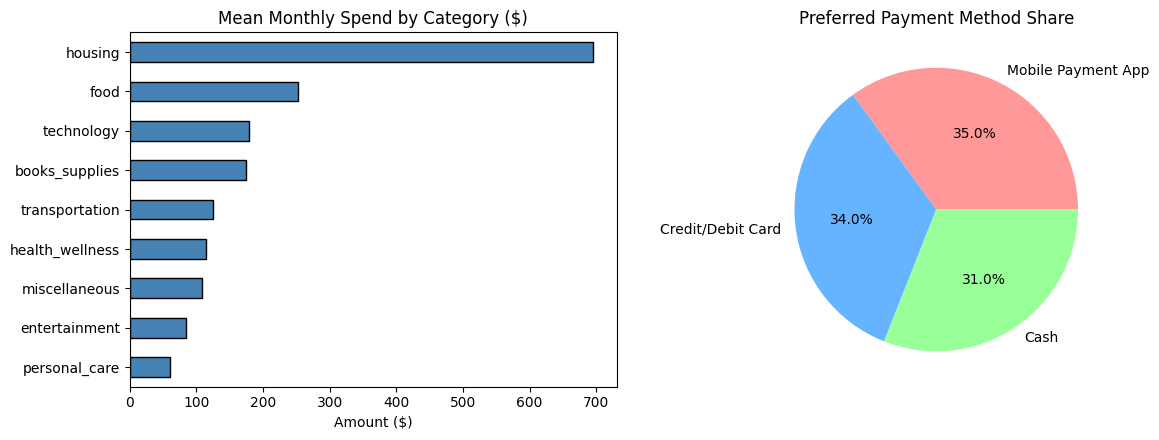

In [5]:
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
mean_spending = df[expense_cols].mean().sort_values(ascending=True)
mean_spending.plot(kind="barh", color="steelblue", edgecolor="black")
plt.title("Mean Monthly Spend by Category ($)")
plt.xlabel("Amount ($)")

plt.subplot(1, 2, 2)
df["preferred_payment_method"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", colors=["#ff9999", "#66b3ff", "#99ff99"]
)
plt.title("Preferred Payment Method Share")
plt.ylabel("")

plt.tight_layout()
plt.show()

# Question 3: Base Model Training and Evaluation (Logistic Regression)

## 3.1 Target Variable Construction (`budget_risk`)

In [6]:
# Verify tuition scale before constructing target
deficit_with_tuition = ((df["total_non_tuition_expenses"] + df["tuition"]) > df["available_funds"]).mean()
deficit_without_tuition = (df["total_non_tuition_expenses"] > df["available_funds"]).mean()

print(f"Mean Available Funds:            ${df['available_funds'].mean():.1f}")
print(f"Mean Non-Tuition Expenses (9):   ${df['total_non_tuition_expenses'].mean():.1f}")
print(f"Mean Tuition:                    ${df['tuition'].mean():.1f}")
print(f"Deficit rate WITH tuition:       {deficit_with_tuition:.3f}")
print(f"Deficit rate WITHOUT tuition:    {deficit_without_tuition:.3f}")

# Binary target: 1 = Deficit / At Risk, 0 = Within Funds
df["budget_risk"] = (df["total_non_tuition_expenses"] > df["available_funds"]).astype(int)

label_names = {0: "Within funds (0)", 1: "At risk / Deficit (1)"}
display(df["budget_risk"].value_counts().sort_index().rename(index=label_names))
display(df["budget_risk"].value_counts(normalize=True).sort_index().rename(index=label_names).round(3))

Mean Available Funds:            $1525.4
Mean Non-Tuition Expenses (9):   $1795.1
Mean Tuition:                    $4520.4
Deficit rate WITH tuition:       1.000
Deficit rate WITHOUT tuition:    0.705


,count
budget_risk,
Within funds (0),295
At risk / Deficit (1),705


,proportion
budget_risk,
Within funds (0),0.295
At risk / Deficit (1),0.705


## 3.2 Feature Selection and Stratified Train/Test Split

In [7]:
# Exclude expense columns, engineered totals, and tuition to prevent target leakage
feature_cols = numeric_features + categorical_features

X = df[feature_cols].copy()
y = df["budget_risk"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Training Set: {X_train.shape} | At-risk proportion: {y_train.mean():.3f}")
print(f"Test Set:     {X_test.shape} | At-risk proportion: {y_test.mean():.3f}")

Training Set: (800, 7) | At-risk proportion: 0.705
Test Set:     (200, 7) | At-risk proportion: 0.705


## 3.3 Preprocessing and Logistic Regression Pipeline

In [8]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

base_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE))
])

## 3.4 Baseline Comparison and 5-Fold Stratified Cross-Validation

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc"
}

def summarize_cv(model, model_name):
    res = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=scoring, return_train_score=True
    )
    summary = {
        metric: f"{res['test_' + metric].mean():.3f} ± {res['test_' + metric].std():.3f}"
        for metric in scoring
    }
    summary["train_accuracy"] = f"{res['train_accuracy'].mean():.3f}"
    return pd.Series(summary, name=model_name), res

baseline_row, baseline_cv_raw = summarize_cv(
    DummyClassifier(strategy="most_frequent"), "Majority-class baseline"
)
logreg_row, logreg_cv_raw = summarize_cv(
    base_model, "Logistic Regression (default C=1, L2)"
)

cv_comparison_table = pd.DataFrame([baseline_row, logreg_row])
display(cv_comparison_table)

,accuracy,precision,recall,f1,roc_auc,train_accuracy
Majority-class baseline,0.705 ± 0.003,0.705 ± 0.003,1.000 ± 0.000,0.827 ± 0.002,0.500 ± 0.000,0.705
"Logistic Regression (default C=1, L2)",0.860 ± 0.034,0.894 ± 0.030,0.910 ± 0.015,0.902 ± 0.023,0.927 ± 0.024,0.872


## 3.5 Regularisation Tuning (L1 vs. L2 Penalty)

In [10]:
if Version(sklearn.__version__) >= Version("1.8"):
    logistic_regularisation_grid = {
        "classifier__l1_ratio": [0.0, 1.0],
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    }
    regularisation_column = "l1_ratio"
else:
    logistic_regularisation_grid = {
        "classifier__penalty": ["l1", "l2"],
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    }
    regularisation_column = "penalty"

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=logistic_regularisation_grid.copy(),
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)
grid_search.fit(X_train, y_train)

all_grid_results = pd.DataFrame(grid_search.cv_results_)
parameter_col = f"param_classifier__{regularisation_column}"
grid_results = all_grid_results[
    [parameter_col, "param_classifier__C", "mean_test_score", "std_test_score"]
].rename(columns={
    parameter_col: regularisation_column,
    "param_classifier__C": "C",
    "mean_test_score": "mean_cv_roc_auc",
    "std_test_score": "std_cv_roc_auc"
})

display(grid_results.pivot(index="C", columns=regularisation_column, values="mean_cv_roc_auc").round(4))

best_model = grid_search.best_estimator_
print(f"Best Parameters: {grid_search.best_params_} | Best CV ROC-AUC: {grid_search.best_score_:.4f}")

penalty,l1,l2
C,,
0.001,0.5000,0.9321
0.010,0.9317,0.9320
0.100,0.9335,0.9298
1.000,0.9297,0.9275
10.000,0.9271,0.9271
100.000,0.9270,0.9271


Best Parameters: {'classifier__C': 0.1, 'classifier__penalty': 'l1'} | Best CV ROC-AUC: 0.9335


## 3.6 Decision Threshold Tuning (Training CV Predictions)

,threshold,precision,recall,f1,false_warnings,missed_risk
0,0.20,0.781,0.988,0.872,156,7
1,0.25,0.805,0.979,0.883,134,12
2,0.30,0.822,0.968,0.889,118,18
3,0.35,0.835,0.963,0.895,107,21
4,0.40,0.856,0.952,0.902,90,27
5,0.45,0.868,0.934,0.900,80,37
6,0.50,0.898,0.924,0.911,59,43
7,0.55,0.906,0.910,0.908,53,51
8,0.60,0.917,0.883,0.900,45,66
9,0.65,0.929,0.862,0.894,37,78


Selected Decision Threshold: 0.40


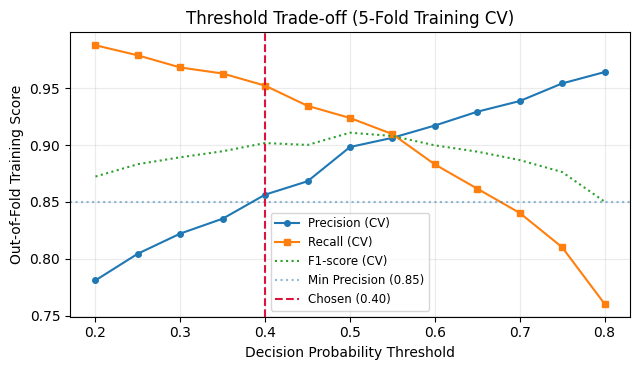

In [11]:
proba_oof_train = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

threshold_rows = []
for t in np.round(np.arange(0.20, 0.81, 0.05), 2):
    pred_oof = (proba_oof_train >= t).astype(int)
    threshold_rows.append({
        "threshold": float(t),
        "precision": precision_score(y_train, pred_oof, zero_division=0),
        "recall": recall_score(y_train, pred_oof, zero_division=0),
        "f1": f1_score(y_train, pred_oof, zero_division=0),
        "false_warnings": int(((pred_oof == 1) & (y_train == 0)).sum()),
        "missed_risk": int(((pred_oof == 0) & (y_train == 1)).sum())
    })

thr_raw_df = pd.DataFrame(threshold_rows)
display(thr_raw_df.round(3))

MIN_PRECISION = 0.85
eligible_thresholds = thr_raw_df[thr_raw_df["precision"] >= MIN_PRECISION]
chosen_threshold = float(
    eligible_thresholds.sort_values(["recall", "precision"], ascending=False)["threshold"].iloc[0]
)
print(f"Selected Decision Threshold: {chosen_threshold:.2f}")

plt.figure(figsize=(6.5, 3.8))
plt.plot(thr_raw_df["threshold"], thr_raw_df["precision"], marker="o", markersize=4, label="Precision (CV)")
plt.plot(thr_raw_df["threshold"], thr_raw_df["recall"], marker="s", markersize=4, label="Recall (CV)")
plt.plot(thr_raw_df["threshold"], thr_raw_df["f1"], linestyle=":", label="F1-score (CV)")
plt.axhline(MIN_PRECISION, color="tab:blue", linestyle=":", alpha=0.5, label=f"Min Precision ({MIN_PRECISION})")
plt.axvline(chosen_threshold, color="crimson", linestyle="--", label=f"Chosen ({chosen_threshold:.2f})")
plt.xlabel("Decision Probability Threshold")
plt.ylabel("Out-of-Fold Training Score")
plt.title("Threshold Trade-off (5-Fold Training CV)")
plt.legend(loc="best", fontsize=8.5)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3.7 Model Testing on Held-Out Test Set

,threshold,accuracy,precision,recall,f1
Default threshold (0.50),0.5,0.88,0.898,0.936,0.917
Chosen threshold (0.40),0.4,0.86,0.865,0.950,0.905


Held-Out Test ROC-AUC: 0.952 | Baseline Test Accuracy: 0.705


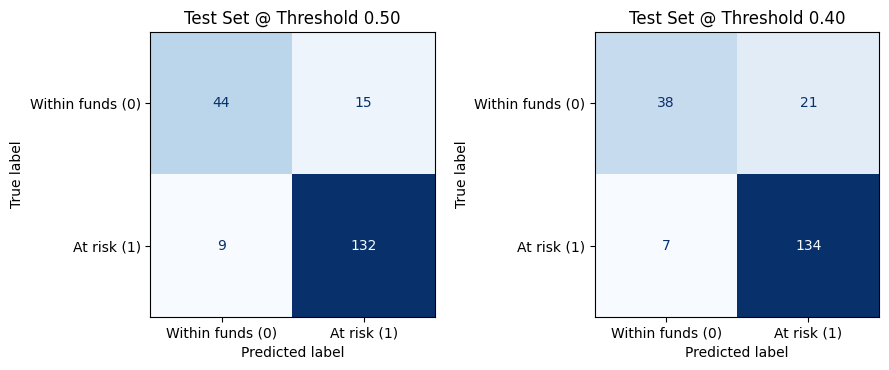

                  precision    recall  f1-score   support

Within funds (0)       0.84      0.64      0.73        59
 Budget risk (1)       0.86      0.95      0.91       141

        accuracy                           0.86       200
       macro avg       0.85      0.80      0.82       200
    weighted avg       0.86      0.86      0.85       200



In [12]:
proba_test = best_model.predict_proba(X_test)[:, 1]
test_roc_auc = roc_auc_score(y_test, proba_test)
test_baseline_acc = max(y_test.mean(), 1.0 - y_test.mean())

def evaluate_on_test(threshold):
    preds = (proba_test >= threshold).astype(int)
    return preds, {
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds, zero_division=0),
        "recall": recall_score(y_test, preds, zero_division=0),
        "f1": f1_score(y_test, preds, zero_division=0)
    }

pred_test_default, metrics_default = evaluate_on_test(0.50)
pred_test_chosen, metrics_chosen = evaluate_on_test(chosen_threshold)

test_summary_df = pd.DataFrame(
    [metrics_default, metrics_chosen],
    index=["Default threshold (0.50)", f"Chosen threshold ({chosen_threshold:.2f})"]
)
display(test_summary_df.round(3))
print(f"Held-Out Test ROC-AUC: {test_roc_auc:.3f} | Baseline Test Accuracy: {test_baseline_acc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
for ax, preds, title in zip(
    axes,
    [pred_test_default, pred_test_chosen],
    ["Test Set @ Threshold 0.50", f"Test Set @ Threshold {chosen_threshold:.2f}"]
):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, preds),
        display_labels=["Within funds (0)", "At risk (1)"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, pred_test_chosen,
    target_names=["Within funds (0)", "Budget risk (1)"],
    zero_division=0
))

## 3.8 Model Feature Coefficients and Target Leakage Check

Intercept: 1.718


,feature,log_odds_coef,odds_ratio_exp_coef
0,num__monthly_income,-1.8113,0.1634
1,num__financial_aid,-1.6785,0.1867
2,num__age,0.0000,1.0000
3,cat__gender_Female,0.0000,1.0000
4,cat__gender_Male,0.0000,1.0000
5,cat__gender_Non-binary,0.0000,1.0000
6,cat__year_in_school_Freshman,0.0000,1.0000
7,cat__year_in_school_Junior,0.0000,1.0000
8,cat__year_in_school_Senior,0.0000,1.0000
9,cat__year_in_school_Sophomore,0.0000,1.0000


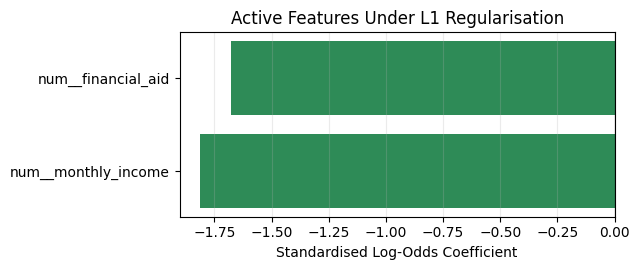

In [13]:
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = best_model.named_steps["classifier"].coef_[0]
intercept_val = best_model.named_steps["classifier"].intercept_[0]

coef_table = pd.DataFrame({
    "feature": feature_names,
    "log_odds_coef": coefficients,
    "odds_ratio_exp_coef": np.exp(coefficients),
    "abs_coef": np.abs(coefficients)
}).sort_values("abs_coef", ascending=False)

print(f"Intercept: {intercept_val:.3f}")
display(coef_table.drop(columns=["abs_coef"]).reset_index(drop=True).round(4))

non_zero_coefs = coef_table[coef_table["log_odds_coef"] != 0].sort_values("log_odds_coef")
if not non_zero_coefs.empty:
    plt.figure(figsize=(6.5, 2.8))
    colors = ["seagreen" if c < 0 else "indianred" for c in non_zero_coefs["log_odds_coef"]]
    plt.barh(non_zero_coefs["feature"], non_zero_coefs["log_odds_coef"], color=colors)
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("Standardised Log-Odds Coefficient")
    plt.title("Active Features Under L1 Regularisation")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

In [14]:
# Target Leakage Verification (Comparing leak-free model vs. model with expense columns included)
leaky_numeric_features = numeric_features + expense_cols

leaky_preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), leaky_numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

leaky_pipeline = Pipeline(steps=[
    ("preprocessor", leaky_preprocessor),
    ("classifier", LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE))
])

X_train_leaky = df.loc[X_train.index, leaky_numeric_features + categorical_features].copy()
X_test_leaky = df.loc[X_test.index, leaky_numeric_features + categorical_features].copy()

leaky_cv = cross_validate(
    leaky_pipeline, X_train_leaky, y_train,
    cv=cv, scoring={"accuracy": "accuracy", "roc_auc": "roc_auc"}
)
leaky_pipeline.fit(X_train_leaky, y_train)
leaky_test_pred = leaky_pipeline.predict(X_test_leaky)
leaky_test_prob = leaky_pipeline.predict_proba(X_test_leaky)[:, 1]

leakage_comparison = pd.DataFrame([
    {
        "Model Setup": "Leak-Free Base Model (Profile + Funds only)",
        "CV Accuracy": logreg_cv_raw["test_accuracy"].mean(),
        "CV ROC-AUC": grid_search.best_score_,
        "Test Accuracy (@ 0.50)": metrics_default["accuracy"],
        "Test ROC-AUC": test_roc_auc
    },
    {
        "Model Setup": "Leaky Model (Includes 9 Expense Columns)",
        "CV Accuracy": leaky_cv["test_accuracy"].mean(),
        "CV ROC-AUC": leaky_cv["test_roc_auc"].mean(),
        "Test Accuracy (@ 0.50)": accuracy_score(y_test, leaky_test_pred),
        "Test ROC-AUC": roc_auc_score(y_test, leaky_test_prob)
    }
])
display(leakage_comparison.round(4))

,Model Setup,CV Accuracy,CV ROC-AUC,Test Accuracy (@ 0.50),Test ROC-AUC
0,Leak-Free Base Model (Profile + Funds only),0.8600,0.9335,0.88,0.9523
1,Leaky Model (Includes 9 Expense Columns),0.9825,0.9991,0.98,0.9995


# Question 4: Further Model Validation and Multi-Algorithm Comparison

## 4.1 Nested Stratified Cross-Validation Across Candidate Classifiers

In [15]:
outer_cv_q4 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_cv_q4 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE + 1)

def build_q4_pipeline(classifier):
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier),
    ])

q4_searches = {
    "Logistic Regression": GridSearchCV(
        estimator=build_q4_pipeline(
            LogisticRegression(solver="saga", max_iter=2000, random_state=RANDOM_STATE)
        ),
        param_grid={
            **{key: value for key, value in logistic_regularisation_grid.items()
               if key != "classifier__C"},
            "classifier__C": [0.01, 0.1, 1, 10],
        },
        scoring="roc_auc", cv=inner_cv_q4, n_jobs=-1, refit=True, error_score="raise"
    ),
    "Decision Tree": GridSearchCV(
        estimator=build_q4_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        param_grid={
            "classifier__max_depth": [3, 5, None],
            "classifier__min_samples_leaf": [5, 10, 20],
            "classifier__class_weight": [None, "balanced"],
        },
        scoring="roc_auc", cv=inner_cv_q4, n_jobs=-1, refit=True, error_score="raise"
    ),
    "Random Forest": GridSearchCV(
        estimator=build_q4_pipeline(
            RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1)
        ),
        param_grid={
            "classifier__max_depth": [None, 10],
            "classifier__min_samples_leaf": [1, 5],
            "classifier__class_weight": [None, "balanced_subsample"],
        },
        scoring="roc_auc", cv=inner_cv_q4, n_jobs=-1, refit=True, error_score="raise"
    ),
    "K-Nearest Neighbours": GridSearchCV(
        estimator=build_q4_pipeline(KNeighborsClassifier()),
        param_grid={
            "classifier__n_neighbors": [5, 11, 21],
            "classifier__weights": ["uniform", "distance"],
        },
        scoring="roc_auc", cv=inner_cv_q4, n_jobs=-1, refit=True, error_score="raise"
    ),
    "Support Vector Machine (RBF)": GridSearchCV(
        estimator=build_q4_pipeline(
            SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
        ),
        param_grid={
            "classifier__C": [0.1, 1, 10],
            "classifier__class_weight": [None, "balanced"],
        },
        scoring="roc_auc", cv=inner_cv_q4, n_jobs=-1, refit=True, error_score="raise"
    ),
}

q4_baseline = build_q4_pipeline(DummyClassifier(strategy="most_frequent"))
q4_candidates = {"Majority-class baseline": q4_baseline, **q4_searches}

q4_cv_rows = []
q4_cv_raw = {}
for model_name, estimator in q4_candidates.items():
    cv_result = cross_validate(
        estimator, X_train, y_train, cv=outer_cv_q4,
        scoring=scoring, return_train_score=False, n_jobs=1, error_score="raise"
    )
    q4_cv_raw[model_name] = cv_result
    row = {"Model": model_name}
    for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        vals = cv_result[f"test_{metric}"]
        row[f"{metric.upper()} (mean ± SD)"] = f"{vals.mean():.3f} ± {vals.std():.3f}"
    q4_cv_rows.append(row)

q4_cv_table = pd.DataFrame(q4_cv_rows).sort_values(
    by="ROC_AUC (mean ± SD)", ascending=False, key=lambda s: s.str.split(" ± ").str[0].astype(float)
).reset_index(drop=True)
display(q4_cv_table)

,Model,ACCURACY (mean ± SD),PRECISION (mean ± SD),RECALL (mean ± SD),F1 (mean ± SD),ROC_AUC (mean ± SD)
0,Logistic Regression,0.872 ± 0.027,0.899 ± 0.023,0.924 ± 0.018,0.911 ± 0.018,0.934 ± 0.023
1,Support Vector Machine (RBF),0.854 ± 0.030,0.917 ± 0.049,0.876 ± 0.037,0.894 ± 0.019,0.926 ± 0.025
2,Random Forest,0.866 ± 0.025,0.919 ± 0.028,0.890 ± 0.018,0.904 ± 0.017,0.918 ± 0.025
3,K-Nearest Neighbours,0.849 ± 0.026,0.866 ± 0.017,0.929 ± 0.024,0.896 ± 0.018,0.913 ± 0.025
4,Decision Tree,0.843 ± 0.051,0.893 ± 0.039,0.883 ± 0.044,0.888 ± 0.037,0.887 ± 0.041
5,Majority-class baseline,0.705 ± 0.003,0.705 ± 0.003,1.000 ± 0.000,0.827 ± 0.002,0.500 ± 0.000


## 4.2 Held-Out Test Set Evaluation Across Candidate Classifiers

In [16]:
q4_final_models = {"Majority-class baseline": q4_baseline, **q4_searches}
q4_test_rows = []
q4_test_predictions = {}

for model_name, estimator in q4_final_models.items():
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    probability = estimator.predict_proba(X_test)[:, 1]
    q4_test_predictions[model_name] = pred

    q4_test_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "Best Parameters": str(estimator.best_params_) if isinstance(estimator, GridSearchCV) else "Most-frequent class",
    })

q4_test_table = pd.DataFrame(q4_test_rows)
q4_cv_order = q4_cv_table["Model"].tolist()
q4_test_table["Model"] = pd.Categorical(q4_test_table["Model"], categories=q4_cv_order, ordered=True)
q4_test_table = q4_test_table.sort_values("Model").reset_index(drop=True)
display(q4_test_table.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Best Parameters
0,Logistic Regression,0.880,0.898,0.936,0.917,0.952,"{'classifier__C': 0.1, 'classifier__penalty': ..."
1,Support Vector Machine (RBF),0.865,0.865,0.957,0.909,0.948,"{'classifier__C': 0.1, 'classifier__class_weig..."
2,Random Forest,0.860,0.931,0.865,0.897,0.934,{'classifier__class_weight': 'balanced_subsamp...
3,K-Nearest Neighbours,0.860,0.874,0.936,0.904,0.936,"{'classifier__n_neighbors': 21, 'classifier__w..."
4,Decision Tree,0.855,0.975,0.816,0.888,0.938,"{'classifier__class_weight': 'balanced', 'clas..."
5,Majority-class baseline,0.705,0.705,1.000,0.827,0.500,Most-frequent class


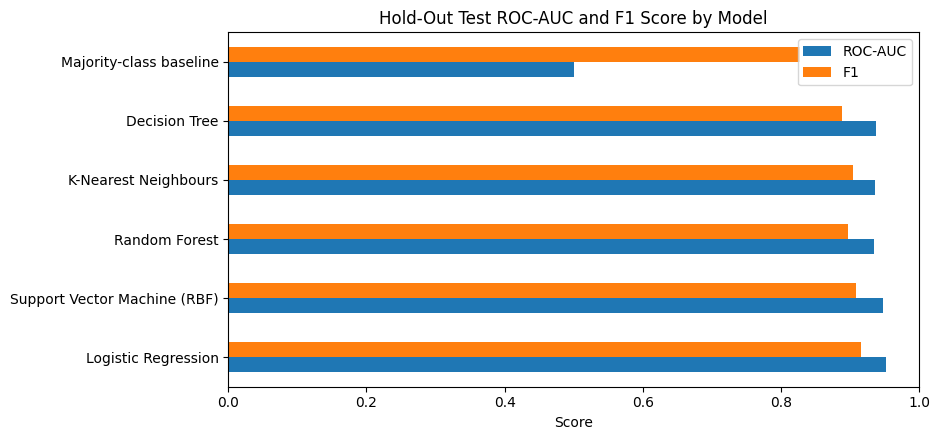

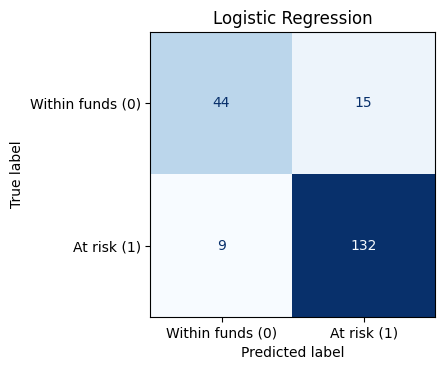

In [17]:
plot_df = q4_test_table.set_index("Model")[["ROC-AUC", "F1"]]
ax = plot_df.plot(kind="barh", figsize=(9.5, 4.5), xlim=(0, 1),
                  title="Hold-Out Test ROC-AUC and F1 Score by Model")
ax.set_xlabel("Score")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

top_models = list(dict.fromkeys(["Logistic Regression", q4_cv_table.iloc[0]["Model"]]))
fig, axes = plt.subplots(1, len(top_models), figsize=(5.5 * len(top_models), 3.8))
if len(top_models) == 1:
    axes = [axes]
for ax, model_name in zip(axes, top_models):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, q4_test_predictions[model_name]),
        display_labels=["Within funds (0)", "At risk (1)"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(model_name)
plt.tight_layout()
plt.show()